In [18]:
from calendar import c
from distutils.command.config import config
import os
import sys

sys.path.insert(0, os.getcwd())

from config_parser import parse_cfg
import argparse
import shutil
from tqdm import tqdm


from tools_for_BOP import bop_io
from bop_dataset_pytorch import bop_dataset_single_obj_pytorch

import torch
import numpy as np
import cv2

sys.path.append("../bop_toolkit")
from bop_toolkit_lib import inout

from model.BinaryCodeNet import BinaryCodeNet_Deeplab

from metric import Calculate_ADD_Error_BOP, Calculate_ADI_Error_BOP

from get_detection_results import ycbv_select_keyframe
from common_ops import from_output_to_class_mask, from_output_to_class_binary_code, compute_original_mask
from tools_for_BOP.common_dataset_info import get_obj_info

from binary_code_helper.generate_new_dict import generate_new_corres_dict

from tools_for_BOP import write_to_cvs 


from binary_code_helper.CNN_output_to_pose import load_dict_class_id_3D_points, CNN_outputs_to_object_pose


In [2]:
import ctypes

# Ubuntu 系统加载 libc.so.6
libc = ctypes.CDLL("libc.so.6")

# 设置随机种子，例如 42
desired_seed = 0
libc.srand(desired_seed)


1

In [14]:
config_file = 'config/config_stripe/lmo/exp_lmo_24_aabb_18_symloss.txt'
checkpoint_file = 'result/checkpoints/exp_lmo_24_aabb_18_symloss/eggbox/checkpoints/best_score/0_7894step98'
eval_output_path = 'result/checkpoints/exp_lmo_24_aabb_18_symloss/eggbox/7894/'
obj_name = 'eggbox'


In [51]:
config_file = 'config/config_stripe/lmo/exp_lmo_24_aabb_18_symloss.txt'
checkpoint_file = 'result/checkpoints/exp_lmo_24_aabb_18_symloss_wrong/glue/checkpoints/best_score/0_9321step200'
eval_output_path = 'result/checkpoints/exp_lmo_24_aabb_18_symloss_wrong/glue/9321/'
obj_name = 'glue'


In [3]:
img_ids = []
scene_ids = []
obj_ids = []
estimated_Rs = []
estimated_Ts = []

In [32]:
config_file = 'config/config_stripe/tless/exp_tless_24_aabb_18_symloss.txt'
checkpoint_file = 'result/checkpoints/exp_tless_24_aabb_18_symloss/obj05/checkpoints/best_score/0_9605step63'
eval_output_path = 'result/checkpoints/exp_tless_24_aabb_18_symloss/obj05/9605_63'
obj_name = 'obj05'


In [365]:
config_file = 'config/config_stripe/tless/exp_tless_24_aabb_18_symloss.txt'
checkpoint_file = 'result/checkpoints/exp_tless_24_aabb_18_symloss/obj06/checkpoints/best_score/0_9694step54'
eval_output_path = 'result/checkpoints/exp_tless_24_aabb_18_symloss/obj06/9694_54'
obj_name = 'obj06'


In [373]:
config_file = 'config/config_stripe/tless/exp_tless_24_aabb_18_symloss.txt'
checkpoint_file = 'result/checkpoints/exp_tless_24_aabb_18_symloss/obj07/checkpoints/best_score/0_9017step48'
eval_output_path = 'result/checkpoints/exp_tless_24_aabb_18_symloss/obj07/9017_48'
obj_name = 'obj07'


In [381]:
config_file = 'config/config_stripe/tless/exp_tless_24_aabb_18_symloss.txt'
checkpoint_file = 'result/checkpoints/exp_tless_24_aabb_18_symloss/obj08/checkpoints/best_score/0_9333step35'
eval_output_path = 'result/checkpoints/exp_tless_24_aabb_18_symloss/obj08/0_9333step35'
obj_name = 'obj08'


In [389]:
config_file = 'config/config_stripe/tless/exp_tless_24_aabb_18_symloss.txt'
checkpoint_file = 'result/checkpoints/exp_tless_24_aabb_18_symloss/obj09/checkpoints/best_score/0_9675step38'
eval_output_path = 'result/checkpoints/exp_tless_24_aabb_18_symloss/obj09/9675_38'
obj_name = 'obj09'


In [397]:
config_file = 'config/config_stripe/tless/exp_tless_24_aabb_18_symloss.txt'
checkpoint_file = 'result/checkpoints/exp_tless_24_aabb_18_symloss/obj10/checkpoints/best_score/0_9650step91'
eval_output_path = 'result/checkpoints/exp_tless_24_aabb_18_symloss/obj10/9650_91'
obj_name = 'obj10'


In [405]:
config_file = 'config/config_stripe/tless/exp_tless_24_aabb_18_symloss.txt'
checkpoint_file = 'result/checkpoints/exp_tless_24_aabb_18_symloss/obj11/checkpoints/best_score/0_9056step72'
eval_output_path = 'result/checkpoints/exp_tless_24_aabb_18_symloss/obj11/9056_72'
obj_name = 'obj11'


In [439]:
config_file = 'config/config_stripe/tless/exp_tless_24_aabb_18_symloss.txt'
checkpoint_file = 'result/checkpoints/exp_tless_24_aabb_18_symloss/obj12/checkpoints/best_score/0_9209step75'
eval_output_path = 'result/checkpoints/exp_tless_24_aabb_18_symloss/obj12/9209_75'
obj_name = 'obj12'


In [51]:
config_file = 'config/config_stripe/geometry/exp_geo_24_aabb_18_symloss.txt'
checkpoint_file = 'result/checkpoints/exp_geo_24_aabb_18_symloss/old_0531/hole_9969/checkpoints/best_score/0_9969step95'
eval_output_path = 'result/checkpoints/exp_tless_24_aabb_18_symloss/obj05/9362_24'
obj_name = 'hole'


In [4]:
config_file = 'config/config_paper/geometry/exp_geo_paper.txt'
checkpoint_file = 'result/checkpoints/exp_geo_paper/hole_9959/checkpoints/best_score/0_9959step100'
eval_output_path = 'result/checkpoints/exp_tless_24_aabb_18_symloss/obj05/9362_24'
obj_name = 'hole'


In [52]:

configs = parse_cfg(config_file)

configs['use_icp'] = False
configs['obj_name'] = obj_name
configs['use_cuda'] = True


if configs['Detection_reaults'] != 'none':
    Detection_reaults = configs['Detection_reaults']
    dirname = os.path.dirname(__file__)
    Detection_reaults = os.path.join(dirname, Detection_reaults)
    configs['Detection_reaults'] = Detection_reaults

configs['checkpoint_file'] = checkpoint_file
configs['eval_output_path'] = eval_output_path

configs['ignore_bit'] = int(0)

#print the configurations
for key in configs:
    print(key, " : ", configs[key], flush=True)

bop_challange  :  False
bop_path  :  datasets/
dataset_name  :  geometry
training_data_folder  :  train_pbr
training_data_folder_2  :  none
val_folder  :  test
test_folder  :  test
second_dataset_ratio  :  0.75
num_workers  :  8
train_obj_visible_theshold  :  0.2
BoundingBox_CropSize_image  :  256
BoundingBox_CropSize_GT  :  128
BinaryCode_Loss_Type  :  BCE
mask_binary_code_loss  :  True
predict_entire_mask  :  False
sym_input_training  :  False
use_confidence  :  False
confidence_threshold  :  0
use_histgramm_weighted_binary_loss  :  True
sym_aware_loss  :  True
sym_bit  :  [0,2]
output_kernel_size  :  1
resnet_layer  :  18
concat_encoder_decoder  :  True
load_pretrain_checkpoint  :  True
pretrain_path  :  zebrapose_lmo/
load_checkpoint  :  False
check_point_path  :  result/checkpoints/
optimizer_type  :  Adam
learning_rate  :  0.0002
batch_size  :  16
total_iteration  :  380000
total_epoch  :  100
binary_loss_weight  :  3
Detection_reaults  :  none
padding_ratio  :  1.5
resize_method

In [53]:
bop_path = configs['bop_path']
num_workers = configs['num_workers']
BinaryCode_Loss_Type = configs['BinaryCode_Loss_Type'] 
dataset_name = configs['dataset_name']
test_folder=configs['test_folder'] 
training_data_folder=configs['training_data_folder']
#### augmentations
Detection_reaults=configs['Detection_reaults']                       # for the test, the detected bounding box provided by GDR Net
padding_ratio=configs['padding_ratio']                               # pad the bounding box for training and test
resize_method = configs['resize_method']                             # how to resize the roi images to 256*256
use_peper_salt= configs['use_peper_salt']                            # if add additional peper_salt in the augmentation
use_motion_blur= configs['use_motion_blur']    
train_obj_visible_theshold = configs['train_obj_visible_theshold']
obj_name_obj_id, symmetry_obj = get_obj_info(dataset_name)
#### network settings
BoundingBox_CropSize_image = configs['BoundingBox_CropSize_image']  # input image size
BoundingBox_CropSize_GT = configs['BoundingBox_CropSize_GT'] 
obj_id = int(obj_name_obj_id[obj_name] - 1) # now the obj_id started from 0
divide_number_each_itration = configs['divide_number_each_itration']
number_of_itration = configs['number_of_itration']
dataset_dir,source_dir,model_plys,model_info,model_ids,rgb_files,depth_files,mask_files,mask_visib_files,gts,gt_infos,cam_param_global, cam_params = bop_io.get_dataset(bop_path,dataset_name, train=True, data_folder=training_data_folder, data_per_obj=True, incl_param=True, train_obj_visible_theshold=train_obj_visible_theshold)
if 'efficientnet_key' in configs.keys():
    efficientnet_key = configs['efficientnet_key']      
else  :
    efficientnet_key = None     
if 'sym_input_training' in configs.keys():
    sym_input_training = configs['sym_input_training']
else:
    sym_input_training = False





mesh_path = model_plys[obj_id+1] # mesh_path is a dict, the obj_id should start from 1
vertices = inout.load_ply(mesh_path)["pts"]

obj_diameter = model_info[str(obj_id+1)]['diameter']
print("obj_diameter", obj_diameter)
path_dict = os.path.join(dataset_dir, "models_GT_color", "Class_CorresPoint{:06d}.txt".format(obj_id+1))
total_numer_class, _, _, dict_class_id_3D_points = load_dict_class_id_3D_points(path_dict)
divide_number_each_itration = int(divide_number_each_itration)
total_numer_class = int(total_numer_class)
number_of_itration = int(number_of_itration)
GT_code_infos = [divide_number_each_itration, number_of_itration, total_numer_class]
if obj_name in symmetry_obj:
    Calculate_Pose_Error_Main = Calculate_ADI_Error_BOP
    Calculate_Pose_Error_Supp = Calculate_ADD_Error_BOP
    main_metric_name = 'ADI'
    supp_metric_name = 'ADD'
else:
    Calculate_Pose_Error_Main = Calculate_ADD_Error_BOP
    Calculate_Pose_Error_Supp = Calculate_ADI_Error_BOP
    main_metric_name = 'ADD'
    supp_metric_name = 'ADI'
# dataset_dir_test,_,_,_,_,test_rgb_files,test_depth_files,test_mask_files,test_mask_visib_files,test_gts,test_gt_infos,_, camera_params_test = bop_io.get_dataset(bop_path, dataset_name,train=False, data_folder=test_folder, data_per_obj=True, incl_param=True, train_obj_visible_theshold=train_obj_visible_theshold)
if Detection_reaults != 'none':
    if configs['detector']=='FCOS':
        from get_detection_results import get_detection_results, get_detection_scores
    elif configs['detector']=='MASKRCNN':
        from get_mask_rcnn_results import get_detection_results, get_detection_scores
    Det_Bbox = get_detection_results(Detection_reaults, test_rgb_files[obj_id], obj_id+1, 0)
    scores = get_detection_scores(Detection_reaults, test_rgb_files[obj_id], obj_id+1, 0)
else:
    Det_Bbox = None
# test_dataset = bop_dataset_single_obj_pytorch(
#                                         dataset_dir_test, test_folder, test_rgb_files[obj_id], test_mask_files[obj_id], test_mask_visib_files[obj_id], 
#                                         test_gts[obj_id], test_gt_infos[obj_id], camera_params_test[obj_id], False, 
#                                         BoundingBox_CropSize_image, BoundingBox_CropSize_GT, GT_code_infos, 
#                                         padding_ratio=padding_ratio, resize_method=resize_method, Detect_Bbox=Det_Bbox,
#                                         use_peper_salt=use_peper_salt, use_motion_blur=use_motion_blur,
#                                         sym_input_training=sym_input_training
#                                         )
# test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=num_workers)


datasets/geometry/models/obj_000001.ply
datasets/geometry/models/obj_000002.ply
datasets/geometry/models/obj_000003.ply
datasets/geometry/models/obj_000004.ply
datasets/geometry/models/obj_000005.ply
if models are not fully listed above, please make sure there are ply files available
obj_diameter 86.99998596518948


In [54]:
def selected_mask_highest(pred_masks, confidence_image):
    B, H, W = confidence_image.shape
    
    # pred_masks: [B, 1, H, W]
    
    # 每张图mask像素数
    mask_pixels = pred_masks.sum(axis=(1, 2, 3))
    # 保留30%，限制在[100, 1000]
    k = np.clip((mask_pixels * 0.3).astype(np.int32),
                a_min=100,
                a_max=1500)
    
    # 展平
    conf_flat = confidence_image.reshape(B, -1)
    
    # 输出mask
    selected_mask = np.zeros_like(conf_flat, dtype=bool)
    
    for b in range(B):
    
        k_b = int(k[b])
    
        # Top-K索引
        idx = np.argpartition(
            conf_flat[b],
            -k_b
        )[-k_b:]
    
        selected_mask[b, idx] = True
    
    # 恢复形状
    selected_mask = selected_mask.reshape(B, H, W)
    return selected_mask


def selected_mask_patch(pred_masks, confidence_image):
    grid_h = 4
    grid_w = 4
    points_per_cell = 250  
    B, H, W = confidence_image.shape
    selected_mask = np.zeros((B,H,W), dtype=bool)
    
    cell_h = H // grid_h
    cell_w = W // grid_w
    
    for b in range(B):
    
        for gy in range(grid_h):
    
            for gx in range(grid_w):
    
                y0 = gy * cell_h
                y1 = min((gy+1)*cell_h, H)
    
                x0 = gx * cell_w
                x1 = min((gx+1)*cell_w, W)
    
                conf_patch = confidence_image[b,y0:y1,x0:x1]
    
                mask_patch = pred_masks[b,0,y0:y1,x0:x1].astype(bool)
    
                if not mask_patch.any():
                    continue
    
                conf_valid = conf_patch[mask_patch]
    
                k = min(
                    int(len(conf_valid) /2),
                    len(conf_valid)
                )
    
                idx = np.argpartition(
                    conf_valid,
                    -k
                )[-k:]
    
                valid_pos = np.flatnonzero(mask_patch)
    
                selected_pos = valid_pos[idx]
    
                patch_mask = selected_mask[b,y0:y1,x0:x1]
    
                patch_mask.flat[selected_pos] = True

    return selected_mask



def bit_confidence(p):
    H = -(p*np.log(p+1e-8)
         +(1-p)*np.log(1-p+1e-8))

    return 1 - H/np.log(2)

# def bit_confidence(p):
#     H = 2 * abs(p-0.5)

#     return H

def calc_prediction_confidence_image(pred_code_prob, pred_masks,class_code_images):
    center = 10
    steepness = 0.6
    B, K, H, W = pred_code_prob.shape

    idx = np.arange(1, K + 1)
    
    w = 1/(1+np.exp(steepness*(idx-center)))
    # w = np.array([1 for i in range(K)])
    w = w/w.sum()

    # 扩展 mask 到 (1,1,128,128) 以匹配 data 的维度
    pred_masks = pred_masks[:, np.newaxis, :, :]   # shape (1, 1, 128, 128)
    activation_function = torch.nn.Sigmoid()
    pred_code_prob = activation_function(pred_code_prob)
    pred_code_prob = pred_code_prob.detach().cpu().numpy()
    # print("max value before normalization: ", np.max(pred_code_prob), " min value before normalization: ", np.min(pred_code_prob), " mean value before normalization: ", np.mean(pred_code_prob))
    pred_bit_confidence = bit_confidence(pred_code_prob) * pred_masks
    
    confidence_image = np.sum(
        pred_bit_confidence * w[None, :, None, None],
        axis=1
    )
    selected_highest_mask = selected_mask_highest(pred_masks, confidence_image)
    selected_patch_mask = selected_mask_patch(pred_masks, confidence_image)
    # selected_mask = selected_highest_mask | selected_patch_mask
    selected_mask = selected_patch_mask
    # selected_mask = selected_highest_mask

    from binary_code_helper.class_id_encoder_decoder import class_code_images_to_class_id_image, class_id_image_to_RGB_image,code_to_BGR_image

    pred_code_prob_ = pred_code_prob[:,:,:,:]
    class_id_image = code_to_BGR_image(pred_code_prob_)
    
    class_id_image = class_id_image[0] * pred_masks[0]
    class_id_image_s = class_id_image * selected_mask
    class_id_image = class_id_image.transpose((1,2,0))
    class_id_image_s = class_id_image_s.transpose((1,2,0))
    print(class_id_image.shape)
    # import cv2
    # cv2.imshow("pred_mask",pred_masks[0][0].astype('uint8')*255)
    # cv2.imshow("confidence_image",cv2.applyColorMap((confidence_image[0]*255).astype('uint8'),cv2.COLORMAP_JET))
    # cv2.imshow("selected_mask",(selected_mask[0]*255).astype('uint8'))
    # cv2.imshow("selected_mask",(selected_mask[0]*255).astype('uint8'))
    # cv2.imshow("selected_patch_mask",(selected_patch_mask[0]*255).astype('uint8'))
    # cv2.imshow("class_id_image",(class_id_image).astype('uint8'))
    
    # cv2.imwrite("confidence_image.jpg",cv2.applyColorMap((confidence_image[0]*255).astype('uint8'),cv2.COLORMAP_JET))
    # cv2.imwrite("class_id_image.jpg",(class_id_image).astype('uint8'))
    # cv2.imwrite("class_id_image_s.jpg",(class_id_image_s).astype('uint8'))
    
    # cv2.imwrite("selected_patch_mask.jpg",(selected_mask[0]*255).astype('uint8'))
    
    # cv2.waitKey(0)
    # cv2.destroyAllWindows()   

    
    # pred_confidence = np.abs(pred_code_prob - 0.5) / 0.5  # normalize to [0,1] [batch_size, code_length, h, w]
    # valid_mask = pred_masks != 0
    # sum_vals = np.sum(pred_confidence * valid_mask, axis=(2,3))
    # count = np.sum(valid_mask, axis=(2,3))
    # pred_confidence_mean = sum_vals / count  # 得到 (batch_size, 24,)
    # # pred_confidence_mean = np.mean(pred_confidence, axis=(0, 2, 3)) 
    # print(pred_confidence_mean)
    # pred_confidence = pred_confidence > pred_confidence_mean[:, :, None, None]
        
    # confidence_image = np.mean(pred_confidence[:,:,:,:], axis=1) # [batch_size, h, w]
    
    # print("max confidence value: ", np.max(confidence_image), " min confidence value: ", np.min(confidence_image), " mean confidence value: ", np.mean(confidence_image))
    return selected_mask        




In [55]:
if not configs['bop_challange']:
    dataset_dir_test,_,_,_,_,test_rgb_files,test_depth_files,test_mask_files,test_mask_visib_files,test_gts,test_gt_infos,_, camera_params_test = bop_io.get_dataset(bop_path, dataset_name,train=False, data_folder=test_folder, data_per_obj=True, incl_param=True, train_obj_visible_theshold=train_obj_visible_theshold)
else:
    dataset_dir_test,_,_,_,_,test_rgb_files,test_depth_files,test_mask_files,test_mask_visib_files,test_gts,test_gt_infos,_, camera_params_test = bop_io.get_bop_challange_test_data(bop_path, dataset_name, target_obj_id=obj_id+1, data_folder=test_folder)

test_img_num = len(test_rgb_files[obj_id])


datasets/geometry/models/obj_000001.ply
datasets/geometry/models/obj_000002.ply
datasets/geometry/models/obj_000003.ply
datasets/geometry/models/obj_000004.ply
datasets/geometry/models/obj_000005.ply
if models are not fully listed above, please make sure there are ply files available


In [56]:
from binary_code_helper.class_id_encoder_decoder import class_code_images_to_class_id_image
import numpy as np
import cv2


def mapping_pixel_position_to_original_position(pixels, Bbox, Bbox_Size):
    """
    The image was cropped and resized. This function returns the original pixel position
    input:
        pixels: pixel position after cropping and resize, which is a numpy array, N*(X, Y)
        Bbox: Bounding box for the cropping, minx miny width height
    """
    ratio_x = Bbox[2] / Bbox_Size
    ratio_y = Bbox[3] / Bbox_Size

    original_pixel_x = ratio_x*pixels[:,0] + Bbox[0]     
    original_pixel_y = ratio_y*pixels[:,1] + Bbox[1] 

    original_pixel_x = original_pixel_x.astype('int')
    original_pixel_y = original_pixel_y.astype('int')

    return np.concatenate((original_pixel_x.reshape(-1, 1), original_pixel_y.reshape(-1, 1)), 1)


def build_non_unique_2D_3D_correspondence(Pixel_position, class_id_image, dict_class_id_3D_points,confidence_image=None,confidence_threshold=0.5):
    Point_2D = np.concatenate((Pixel_position[1].reshape(-1, 1), Pixel_position[0].reshape(-1, 1)), 1)   #(npoint x 2)
    
    ids_for_searching = class_id_image[Point_2D[:, 1], Point_2D[:, 0]]

    Points_3D = np.zeros((Point_2D.shape[0],3))
    row = []
    num_1 = 0
    num_2 = 0
    for i in range(Point_2D.shape[0]):
        if dict_class_id_3D_points[ids_for_searching[i]] is None: 
            row.append(i)    
            num_1 += 1
            continue        
        if confidence_image is not None:
            if confidence_image[Point_2D[i,1], Point_2D[i,0]] < confidence_threshold:
                row.append(i)   
                num_2 += 1        
                continue
        Points_3D[i] = np.array(dict_class_id_3D_points[ids_for_searching[i]])
    Point_2D = np.delete(Point_2D, row, axis=0)
    Points_3D = np.delete(Points_3D, row, axis=0)
    print("remove {} points".format(len(row)),",{} points left".format(Point_2D.shape[0]))
    print("remove {} points due to missing 3D points".format(num_1))
    print("remove {} points due to low confidence".format(num_2))
    return Point_2D, Points_3D


def build_unique_2D_3D_correspondence(Pixel_position, class_id_image, dict_class_id_3D_points):
    # if multiple 2D pixel match to a 3D vertex. For this vertex, its corres pixel will be the mean position of those pixels

    Point_2D = np.concatenate((Pixel_position[1].reshape(-1, 1), Pixel_position[0].reshape(-1, 1)), 1)   #(npoint x 2)
    ids_for_searching = class_id_image[Point_2D[:, 1], Point_2D[:, 0]]

    #build a dict for 3D points and all 2D pixel
    unique_3D_2D_corres = {}
    for i in range(Point_2D.shape[0]):      
        if ids_for_searching[i] in unique_3D_2D_corres.keys():
            unique_3D_2D_corres[ids_for_searching[i]].append(Point_2D[i])
        else:
            unique_3D_2D_corres[ids_for_searching[i]] = [Point_2D[i]]

    Points_3D = np.zeros((len(unique_3D_2D_corres),3))
    Points_2D = np.zeros((len(unique_3D_2D_corres),2))
    for counter, (key, value) in enumerate(unique_3D_2D_corres.items()):
        Points_3D[counter] = dict_class_id_3D_points[key]
        sum_Pixel_2D = np.zeros((1,2))
        for Pixel_2D in value:
            sum_Pixel_2D = sum_Pixel_2D + Pixel_2D
        unique_Pixel_2D = sum_Pixel_2D / len(value)
        Points_2D[counter] = unique_Pixel_2D

    return Points_2D, Points_3D


def get_class_id_image_validmask(class_id_image):
    mask_image = np.zeros(class_id_image.shape)
    mask_image[class_id_image.nonzero()]=1
    return mask_image



def CNN_outputs_to_object_pose_ransac_pnp(mask_image, class_code_image,confidence_image, confidence_threshold, Bbox, Bbox_Size, class_base=2, dict_class_id_3D_points=None, intrinsic_matrix=None):
    if intrinsic_matrix is None:
        intrinsic_matrix = np.zeros((3,3))

        intrinsic_matrix[0,0] = 572.4114             #fx
        intrinsic_matrix[1,1] = 573.57043            #fy
        intrinsic_matrix[0,2] = 325.2611             #cx
        intrinsic_matrix[1,2] = 242.04899            #cy
        intrinsic_matrix[2,2] = 1.0 

    class_id_image = class_code_images_to_class_id_image(class_code_image, class_base)
    Points_2D = mask_image.nonzero()
        
    # find the 2D-3D correspondences and Ransac + PnP
    build_2D_3D_correspondence = build_non_unique_2D_3D_correspondence
    success = False
    rot = []
    tvecs = []

    if Points_2D[0].size != 0:   
        Points_2D,  Points_3D = build_2D_3D_correspondence(Points_2D, class_id_image, dict_class_id_3D_points,confidence_image,confidence_threshold)
        # PnP needs atleast 6 unique 2D-3D correspondences to run
        # mapping the pixel position to its original position
      
        Original_Points_2D = mapping_pixel_position_to_original_position(Points_2D, Bbox, Bbox_Size)
        if len(Original_Points_2D) >= 6:
            success = True
            coord_2d = np.ascontiguousarray(Original_Points_2D.astype(np.float32))
            coord_3d = np.ascontiguousarray(Points_3D.astype(np.float32))
            intrinsic_matrix = np.ascontiguousarray(intrinsic_matrix)

            # Fast RANSAC-PnP
            try:
                # Ensure contiguous arrays
                coord_2d = np.ascontiguousarray(
                    Original_Points_2D, dtype=np.float32
                ).reshape(-1, 2)
            
                coord_3d = np.ascontiguousarray(
                    Points_3D, dtype=np.float32
                ).reshape(-1, 3)
            
                K = np.ascontiguousarray(
                    intrinsic_matrix, dtype=np.float64
                )
            
                # Check correspondence number
                if len(coord_2d) >= 6 and len(coord_3d) == len(coord_2d):
            
                    pnp_success, rvecs, tvecs, inliers = cv2.solvePnPRansac(
                        objectPoints=coord_3d,
                        imagePoints=coord_2d,
                        cameraMatrix=K,
                        distCoeffs=None,
                        iterationsCount=100,
                        reprojectionError=3.0,
                        confidence=0.99,
                        flags=cv2.SOLVEPNP_EPNP
                    )
            
                    if pnp_success and inliers is not None and len(inliers) >= 6:
            
                        # Refine pose using inliers
                        inlier_idx = inliers.reshape(-1)
            
                        inlier_3d = coord_3d[inlier_idx]
                        inlier_2d = coord_2d[inlier_idx]
            
                        # Levenberg-Marquardt refinement
                        rvecs, tvecs = cv2.solvePnPRefineLM(
                            inlier_3d,
                            inlier_2d,
                            K,
                            None,
                            rvecs,
                            tvecs
                        )
            
                        # Rodrigues: rotation vector -> rotation matrix
                        rot, _ = cv2.Rodrigues(rvecs)
            
                        success = True
            
                    else:
                        rot = np.zeros((3, 3))
                        tvecs = np.zeros((3, 1))
                        success = False
            
                else:
                    rot = np.zeros((3, 3))
                    tvecs = np.zeros((3, 1))
                    success = False
            
            except cv2.error:
                rot = np.zeros((3, 3))
                tvecs = np.zeros((3, 1))
                success = False
    return rot, tvecs, success



In [57]:

use_confidence = True
confidence_threshold = 0.9


i = 0
counter = 0
ADX_passed = 0
ADX_passed_5 = 0
ADX_passed_25 = 0
# for batch_idx, (data, entire_masks, masks, Rs, ts, Bboxes, class_code_images, cam_Ks) in enumerate(tqdm(test_loader)):
    # i += 1
    # if i == 20:
    #     break
    # data=data.cuda()
    # masks = masks.cuda()
    # class_code_images = class_code_images.cuda()
fail_img = []
success_img = []
estimated_Rs = []
estimated_Ts = []
import time
times = []

# list = [30, 36, 39, 40, 43, 48, 67, 74, 93, 94, 121, 122, 133, 136, 137, 180, 181, 182, 187]
# list = [39, 40, 43, 48, 67, 74, 93, 94, 121, 127, 133, 136, 137, 180,181, 182, 188]
# list = [0, 4, 5, 8, 9, 10, 11, 12, 13, 14, 16, 21, 23, 26, 27, 28, 33, 34, 36, 43, 51, 59, 60, 67, 68, 69, 79, 80, 81, 83, 84, 85, 86, 87, 89, 92, 94, 95, 96, 97, 98, 99, 101, 107, 108, 110, 111, 113, 119, 120, 121, 122, 123, 127, 129, 130, 131, 132, 133, 136, 138, 143, 144, 149, 150, 154, 155, 156, 157, 158, 160, 162, 167]
list = [0]
# list = [107, 111, 113, 122, 132]
# list = [18, 22, 27, 35, 36, 38, 43, 47, 52, 54, 55]
# for i in list:


for i in range(test_img_num):
    print(i)
    data = np.load('img_'+obj_name+ f'/{i}_output_data_compressed.npz')

    pred_code_prob = torch.from_numpy(data['pred_code_prob']).cuda()
    pred_masks = data['pred_masks']
    masks = torch.from_numpy(data['real_masks']).cuda()
    class_code_images = data['real_code_images']
    pred_code_images = data['pred_code_images']
    Rs = data['Rs']
    ts = data['ts']
    Bboxes = data['Bboxes']
    cam_Ks = torch.from_numpy(data['cam_Ks'])


    confidence_image = np.ones((pred_code_prob.shape[0], pred_code_prob.shape[2], pred_code_prob.shape[3]), dtype=np.float32)
    
    if use_confidence and (BinaryCode_Loss_Type == "BCE" or BinaryCode_Loss_Type == "L1"): 
        confidence_image = calc_prediction_confidence_image(pred_code_prob,pred_masks,class_code_images)


    for counter, (r_GT, t_GT, Bbox, cam_K) in enumerate(zip(Rs, ts, Bboxes, cam_Ks)):
        
        confidence_image[counter]
        start_time = time.time()
        
        # R_predict, t_predict, success = CNN_outputs_to_object_pose(pred_masks[counter], pred_code_images[counter], confidence_image[counter], confidence_threshold,
        #                                                             Bbox, BoundingBox_CropSize_GT, divide_number_each_itration, dict_class_id_3D_points, 
        #                                                             intrinsic_matrix=cam_K)
        R_predict, t_predict, success = CNN_outputs_to_object_pose_ransac_pnp(pred_masks[counter], pred_code_images[counter], confidence_image[counter], confidence_threshold,
                                                                    Bbox, BoundingBox_CropSize_GT, divide_number_each_itration, dict_class_id_3D_points, 
                                                                    intrinsic_matrix=cam_K)
        end_time = time.time()
        times.append((end_time - start_time) * 1000)
        if success:     
            estimated_Rs.append(R_predict)
            estimated_Ts.append(t_predict)
        else:
            R_ = np.zeros((3,3))
            R_[0,0] = 1
            R_[1,1] = 1
            R_[2,2] = 1
            estimated_Rs.append(R_)
            estimated_Ts.append(np.zeros((3,1)))
        
        adx_error = 10000
        if success:
            adx_error = Calculate_Pose_Error_Main(r_GT, t_GT, R_predict, t_predict, vertices)
            if np.isnan(adx_error):
                adx_error = 10000
        print(adx_error)
        if adx_error < obj_diameter*0.1:
            ADX_passed += 1
            print("----------- success 0.1 --------------")
            success_img.append(i)
            
        else:
            fail_img.append(i)
        if adx_error < obj_diameter*0.05:
            ADX_passed_5 += 1
            print("----------- success 0.05 --------------")
        if adx_error < obj_diameter*0.025:
            ADX_passed_25 += 1
            print("----------- success 0.025 --------------")
        
    
        activation_function = torch.nn.Sigmoid()
        pred_code_prob = activation_function(pred_code_prob)
        pred_code_prob = torch.where(pred_code_prob < 0.5, 1 - pred_code_prob, pred_code_prob)
        pred_code_prob = pred_code_prob.detach().cpu().numpy() * 255
        # print(pred_code_prob)
        masks = masks.cpu().detach().numpy()
        true_prob_image = pred_code_images == class_code_images
        false_prob_image = pred_code_images == (1 - class_code_images)

        # import cv2
        # cv2.imshow("mask",masks[counter].astype('uint8')*255)
        # # cv2.imshow("rgb",data[counter][:3,:,:].cpu().detach().permute(1,2,0).numpy())
        # cv2.imshow("pred_mask",pred_masks[counter].astype('uint8')*255)
        # cv2.imshow("confidence_image",cv2.applyColorMap((confidence_image[counter]*255).astype('uint8'),cv2.COLORMAP_JET))
    
        # num_classes = 6  # 0 ~ 23 共24类，可根据实际修改
        # for c in range(0, 6):
        #     # 显示 true
        #     cv2.imshow(f"{c}_",pred_code_images[counter,:,:,c])
    
        #     cv2.imshow(f"{i}_{c}_true",
        #                 cv2.applyColorMap(np.clip(pred_code_prob[counter, c, :, :] * masks[counter] * true_prob_image[counter, :, :, c],
        #                                             0, 255).astype('uint8'),
        #                                             cv2.COLORMAP_JET))
        #     # 显示 false
        #     cv2.imshow(f"{i}_{c}_false",
        #             cv2.applyColorMap(np.clip(pred_code_prob[counter, c, :, :] * masks[counter] * false_prob_image[counter, :, :, c],
        #                                         0, 255).astype('uint8'),
        #                                 cv2.COLORMAP_JET))
            
            
        #     # # 保存 true 图片（按你的例子只保存了 0_true.png，如果要保存全部，去掉注释）
        #     # cv2.imwrite(f"img/{batch_idx}_{c}_true.png", cv2.applyColorMap(np.clip(pred_code_prob[counter, c, :, :] * masks[counter] * true_prob_image[counter, :, :, c],
        #     #                                     0, 255).astype('uint8'),
        #     #                             cv2.COLORMAP_JET))
        #     # cv2.imwrite(f"img/{batch_idx}_{c}_false.png", cv2.applyColorMap(np.clip(pred_code_prob[counter, c, :, :] * masks[counter] * false_prob_image[counter, :, :, c],
        #     #                                     0, 255).astype('uint8'),
        #     #                             cv2.COLORMAP_JET))    
        # cv2.waitKey(0)
        # cv2.destroyAllWindows()               


print(obj_name)
print("ADX_passed:",ADX_passed)
print("ADX_passed_5:",ADX_passed_5)
print("ADX_passed_25:",ADX_passed_25)
print(fail_img)
print(success_img)


times = np.array(times)

mean_time = np.mean(times)
median_time = np.median(times)
std_time = np.std(times)
min_time = np.min(times)
p95_time = np.percentile(times, 95)

fps = 1000.0 / mean_time

print("\n========== Inference Speed ==========")
print("Input Size:       1 x 3 x 256 x 256")
print("Iterations:       ", test_img_num)
print("Mean Latency:     {:.3f} ms".format(mean_time))
print("Median Latency:   {:.3f} ms".format(median_time))
print("Std Latency:      {:.3f} ms".format(std_time))
print("Min Latency:      {:.3f} ms".format(min_time))
print("P95 Latency:      {:.3f} ms".format(p95_time))
print("FPS:              {:.2f}".format(fps))
print("====================================")

0


RuntimeError: CUDA error: unspecified launch failure
CUDA kernel errors might be asynchronously reported at some other API call,so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1.

In [42]:
#confidence False
#ransacpnp
print(obj_name)
print("ADX_passed:",ADX_passed)
print("ADX_passed_5:",ADX_passed_5)
print("ADX_passed_25:",ADX_passed_25)
print(fail_img)
# print(success_img)
print(ADX_passed / test_img_num)
print("平均耗时:", (end_time - start_time)/test_img_num, "s")


times = np.array(times)

mean_time = np.mean(times)
median_time = np.median(times)
std_time = np.std(times)
min_time = np.min(times)
p95_time = np.percentile(times, 95)

fps = 1000.0 / mean_time

print("\n========== Inference Speed ==========")
print("Input Size:       1 x 3 x 256 x 256")
print("Iterations:       ", test_img_num)
print("Mean Latency:     {:.3f} ms".format(mean_time))
print("Median Latency:   {:.3f} ms".format(median_time))
print("Std Latency:      {:.3f} ms".format(std_time))
print("Min Latency:      {:.3f} ms".format(min_time))
print("P95 Latency:      {:.3f} ms".format(p95_time))
print("FPS:              {:.2f}".format(fps))
print("====================================")

obj05
ADX_passed: 176
ADX_passed_5: 136
ADX_passed_25: 77
[40, 43, 48, 74, 94, 121, 133, 136, 137, 180, 181, 182, 188, 189]
0.9263157894736842
平均耗时: 3.574145467657792e-05 s

========== Inference Speed ==========
Input Size:       1 x 3 x 256 x 256
Iterations:        190
Mean Latency:     10.614 ms
Median Latency:   10.888 ms
Std Latency:      2.389 ms
Min Latency:      3.233 ms
P95 Latency:      14.453 ms
FPS:              94.21


In [50]:
#confidence True
# ransacpnp
print(obj_name)
print("ADX_passed:",ADX_passed)
print("ADX_passed_5:",ADX_passed_5)
print("ADX_passed_25:",ADX_passed_25)
print(fail_img)
# print(success_img)
print(ADX_passed / test_img_num)
print("平均耗时:", (end_time - start_time)/test_img_num, "s")


times = np.array(times)

mean_time = np.mean(times)
median_time = np.median(times)
std_time = np.std(times)
min_time = np.min(times)
p95_time = np.percentile(times, 95)

fps = 1000.0 / mean_time

print("\n========== Inference Speed ==========")
print("Input Size:       1 x 3 x 256 x 256")
print("Iterations:       ", test_img_num)
print("Mean Latency:     {:.3f} ms".format(mean_time))
print("Median Latency:   {:.3f} ms".format(median_time))
print("Std Latency:      {:.3f} ms".format(std_time))
print("Min Latency:      {:.3f} ms".format(min_time))
print("P95 Latency:      {:.3f} ms".format(p95_time))
print("FPS:              {:.2f}".format(fps))
print("====================================")

obj05
ADX_passed: 175
ADX_passed_5: 138
ADX_passed_25: 77
[39, 40, 43, 48, 74, 94, 121, 133, 136, 137, 180, 181, 182, 187, 188]
0.9210526315789473
平均耗时: 5.832596829063014e-05 s

========== Inference Speed ==========
Input Size:       1 x 3 x 256 x 256
Iterations:        190
Mean Latency:     44.653 ms
Median Latency:   45.527 ms
Std Latency:      13.068 ms
Min Latency:      4.913 ms
P95 Latency:      63.536 ms
FPS:              22.40


In [46]:
#confidence True
#


print(obj_name)
print("ADX_passed:",ADX_passed)
print("ADX_passed_5:",ADX_passed_5)
print("ADX_passed_25:",ADX_passed_25)
print(fail_img)
# print(success_img)
print(ADX_passed / test_img_num)
print("平均耗时:", (end_time - start_time)/test_img_num, "s")


times = np.array(times)

mean_time = np.mean(times)
median_time = np.median(times)
std_time = np.std(times)
min_time = np.min(times)
p95_time = np.percentile(times, 95)

fps = 1000.0 / mean_time

print("\n========== Inference Speed ==========")
print("Input Size:       1 x 3 x 256 x 256")
print("Iterations:       ", test_img_num)
print("Mean Latency:     {:.3f} ms".format(mean_time))
print("Median Latency:   {:.3f} ms".format(median_time))
print("Std Latency:      {:.3f} ms".format(std_time))
print("Min Latency:      {:.3f} ms".format(min_time))
print("P95 Latency:      {:.3f} ms".format(p95_time))
print("FPS:              {:.2f}".format(fps))
print("====================================")

obj05
ADX_passed: 175
ADX_passed_5: 137
ADX_passed_25: 77
[39, 40, 43, 48, 74, 94, 121, 133, 136, 137, 180, 181, 182, 187, 188]
0.9210526315789473
平均耗时: 3.065937443783409e-05 s

========== Inference Speed ==========
Input Size:       1 x 3 x 256 x 256
Iterations:        190
Mean Latency:     25.389 ms
Median Latency:   25.584 ms
Std Latency:      7.388 ms
Min Latency:      2.698 ms
P95 Latency:      36.356 ms
FPS:              39.39


In [44]:
#confidence false

print(obj_name)
print("ADX_passed:",ADX_passed)
print("ADX_passed_5:",ADX_passed_5)
print("ADX_passed_25:",ADX_passed_25)
print(fail_img)
# print(success_img)
print(ADX_passed / test_img_num)
print("平均耗时:", (end_time - start_time)/test_img_num, "s")


times = np.array(times)

mean_time = np.mean(times)
median_time = np.median(times)
std_time = np.std(times)
min_time = np.min(times)
p95_time = np.percentile(times, 95)

fps = 1000.0 / mean_time

print("\n========== Inference Speed ==========")
print("Input Size:       1 x 3 x 256 x 256")
print("Iterations:       ", test_img_num)
print("Mean Latency:     {:.3f} ms".format(mean_time))
print("Median Latency:   {:.3f} ms".format(median_time))
print("Std Latency:      {:.3f} ms".format(std_time))
print("Min Latency:      {:.3f} ms".format(min_time))
print("P95 Latency:      {:.3f} ms".format(p95_time))
print("FPS:              {:.2f}".format(fps))
print("====================================")

obj05
ADX_passed: 178
ADX_passed_5: 141
ADX_passed_25: 83
[40, 43, 48, 74, 121, 127, 133, 137, 180, 181, 182, 188]
0.9368421052631579
平均耗时: 4.63448072734632e-05 s

========== Inference Speed ==========
Input Size:       1 x 3 x 256 x 256
Iterations:        190
Mean Latency:     51.943 ms
Median Latency:   50.678 ms
Std Latency:      20.677 ms
Min Latency:      2.936 ms
P95 Latency:      83.359 ms
FPS:              19.25


In [44]:
scene_ids = []
img_ids = []



for rgb_fn in test_rgb_files[obj_id]:
    rgb_fn = rgb_fn.split("/")
    scene_id = rgb_fn[-3]
    img_id = rgb_fn[-1].split(".")[0]
    img_ids.append(img_id)
    scene_ids.append(scene_id)
    obj_ids.append(obj_id+1)


scores = [1 for x in range(len(estimated_Rs))]

print(len(scene_ids),len(img_ids),len(estimated_Rs),len(estimated_Ts),len(scores))




135 135 135 135 135


In [45]:
cvs_path = os.path.join('z_pose_result_bop', 'lmo_result/')
if not os.path.exists(cvs_path):
    os.makedirs(cvs_path)

method = 'stripepose'

In [35]:
write_to_cvs.write_cvs(cvs_path, method + "_{}-test_{}_patch".format(dataset_name, obj_name), obj_id+1, scene_ids, img_ids, estimated_Rs, estimated_Ts, scores)


In [55]:
write_to_cvs.write_cvs(cvs_path, method + "_{}-test_{}_patch_without_space".format(dataset_name, obj_name), obj_id+1, scene_ids, img_ids, estimated_Rs, estimated_Ts, scores)


In [48]:
write_to_cvs.write_cvs(cvs_path, method + "_{}-test_{}_patch_without_bit_weight".format(dataset_name, obj_name), obj_id+1, scene_ids, img_ids, estimated_Rs, estimated_Ts, scores)


In [43]:
write_to_cvs.write_cvs(cvs_path, method + "_{}-test_{}_patch_without_entropy".format(dataset_name, obj_name), obj_id+1, scene_ids, img_ids, estimated_Rs, estimated_Ts, scores)


In [241]:
write_to_cvs.write_cvs(cvs_path, method + "_{}-test_{}_highest".format(dataset_name, obj_name), obj_id+1, scene_ids, img_ids, estimated_Rs, estimated_Ts, scores)


In [246]:
write_to_cvs.write_cvs(cvs_path, method + "_{}-test_{}_highest_or_patch".format(dataset_name, obj_name), obj_id+1, scene_ids, img_ids, estimated_Rs, estimated_Ts, scores)


In [46]:
write_to_cvs.write_cvs(cvs_path, method + "_{}-test_{}".format(dataset_name, obj_name), obj_id+1, scene_ids, img_ids, estimated_Rs, estimated_Ts, scores)


In [4]:
import numpy as np
import os

#scene_id,im_id,obj_id,score,R,t,time

def write_cvs_all(evaluation_result_path, filename, obj_ids, scene_id_, img_id_, r_, t_, scores):
    filename = os.path.join(evaluation_result_path, filename + '.csv')
    f = open(filename, "w")
    f.write("scene_id,im_id,obj_id,score,R,t,time\n")

    for scene_id, img_id,obj_id, r, t, score in zip(scene_id_, img_id_,obj_ids, r_, t_, scores):
        if score == -1:
            continue
        r11 = r[0][0]
        r12 = r[0][1]
        r13 = r[0][2]

        r21 = r[1][0]
        r22 = r[1][1]
        r23 = r[1][2]

        r31 = r[2][0]
        r32 = r[2][1]
        r33 = r[2][2]

        f.write(str(scene_id))
        f.write(",")
        f.write(str(img_id))
        f.write(",")
        f.write(str(obj_id))
        f.write(",")
        f.write(str(score)) # score
        f.write(",")
        # R
        f.write(str(r11))
        f.write(" ")
        f.write(str(r12))
        f.write(" ")
        f.write(str(r13))
        f.write(" ")
        f.write(str(r21))
        f.write(" ")
        f.write(str(r22))
        f.write(" ")
        f.write(str(r23))
        f.write(" ")
        f.write(str(r31))
        f.write(" ")
        f.write(str(r32))
        f.write(" ")
        f.write(str(r33))
        f.write(",")
        #t
        f.write(str(t[0][0]))
        f.write(" ")
        f.write(str(t[1][0]))
        f.write(" ")
        f.write(str(t[2][0]))
        f.write(",")
        #time
        f.write("-1\n")
    f.close()

In [8]:

img_ids = []
scene_ids = []
obj_ids = []
estimated_Rs = []
estimated_Ts = []
use_confidence = False
ADX_passed = 0
ADX_passed_5 = 0
ADX_passed_25 = 0
for obj_name in ['obj05','obj06','obj07','obj08','obj09','obj10','obj11','obj12']:
    config_file = 'config/config_stripe/tless/exp_tless_24_aabb_18_symloss.txt'
        
    configs = parse_cfg(config_file)
    
    configs['use_icp'] = False
    configs['obj_name'] = obj_name
    configs['use_cuda'] = True
    
    
    if configs['Detection_reaults'] != 'none':
        Detection_reaults = configs['Detection_reaults']
        dirname = os.path.dirname(__file__)
        Detection_reaults = os.path.join(dirname, Detection_reaults)
        configs['Detection_reaults'] = Detection_reaults
    
    # configs['checkpoint_file'] = checkpoint_file
    # configs['eval_output_path'] = eval_output_path
    
    configs['ignore_bit'] = int(0)
    
    #print the configurations
    for key in configs:
        print(key, " : ", configs[key], flush=True)

    
    
    bop_path = configs['bop_path']
    num_workers = configs['num_workers']
    BinaryCode_Loss_Type = configs['BinaryCode_Loss_Type'] 
    dataset_name = configs['dataset_name']
    test_folder=configs['test_folder'] 
    training_data_folder=configs['training_data_folder']
    #### augmentations
    Detection_reaults=configs['Detection_reaults']                       # for the test, the detected bounding box provided by GDR Net
    padding_ratio=configs['padding_ratio']                               # pad the bounding box for training and test
    resize_method = configs['resize_method']                             # how to resize the roi images to 256*256
    use_peper_salt= configs['use_peper_salt']                            # if add additional peper_salt in the augmentation
    use_motion_blur= configs['use_motion_blur']    
    train_obj_visible_theshold = configs['train_obj_visible_theshold']
    obj_name_obj_id, symmetry_obj = get_obj_info(dataset_name)
    #### network settings
    BoundingBox_CropSize_image = configs['BoundingBox_CropSize_image']  # input image size
    BoundingBox_CropSize_GT = configs['BoundingBox_CropSize_GT'] 
    obj_id = int(obj_name_obj_id[obj_name] - 1) # now the obj_id started from 0
    divide_number_each_itration = configs['divide_number_each_itration']
    number_of_itration = configs['number_of_itration']
    dataset_dir,source_dir,model_plys,model_info,model_ids,rgb_files,depth_files,mask_files,mask_visib_files,gts,gt_infos,cam_param_global, cam_params = bop_io.get_dataset(bop_path,dataset_name, train=True, data_folder=training_data_folder, data_per_obj=True, incl_param=True, train_obj_visible_theshold=train_obj_visible_theshold)
    if 'efficientnet_key' in configs.keys():
        efficientnet_key = configs['efficientnet_key']      
    else  :
        efficientnet_key = None     
    if 'sym_input_training' in configs.keys():
        sym_input_training = configs['sym_input_training']
    else:
        sym_input_training = False
    
    
    
    
    
    mesh_path = model_plys[obj_id+1] # mesh_path is a dict, the obj_id should start from 1
    vertices = inout.load_ply(mesh_path)["pts"]
    
    obj_diameter = model_info[str(obj_id+1)]['diameter']
    print("obj_diameter", obj_diameter)
    path_dict = os.path.join(dataset_dir, "models_GT_color", "Class_CorresPoint{:06d}.txt".format(obj_id+1))
    total_numer_class, _, _, dict_class_id_3D_points = load_dict_class_id_3D_points(path_dict)
    divide_number_each_itration = int(divide_number_each_itration)
    total_numer_class = int(total_numer_class)
    number_of_itration = int(number_of_itration)
    GT_code_infos = [divide_number_each_itration, number_of_itration, total_numer_class]
    if obj_name in symmetry_obj:
        Calculate_Pose_Error_Main = Calculate_ADI_Error_BOP
        Calculate_Pose_Error_Supp = Calculate_ADD_Error_BOP
        main_metric_name = 'ADI'
        supp_metric_name = 'ADD'
    else:
        Calculate_Pose_Error_Main = Calculate_ADD_Error_BOP
        Calculate_Pose_Error_Supp = Calculate_ADI_Error_BOP
        main_metric_name = 'ADD'
        supp_metric_name = 'ADI'
    # dataset_dir_test,_,_,_,_,test_rgb_files,test_depth_files,test_mask_files,test_mask_visib_files,test_gts,test_gt_infos,_, camera_params_test = bop_io.get_dataset(bop_path, dataset_name,train=False, data_folder=test_folder, data_per_obj=True, incl_param=True, train_obj_visible_theshold=train_obj_visible_theshold)
    if Detection_reaults != 'none':
        if configs['detector']=='FCOS':
            from get_detection_results import get_detection_results, get_detection_scores
        elif configs['detector']=='MASKRCNN':
            from get_mask_rcnn_results import get_detection_results, get_detection_scores
        Det_Bbox = get_detection_results(Detection_reaults, test_rgb_files[obj_id], obj_id+1, 0)
        scores = get_detection_scores(Detection_reaults, test_rgb_files[obj_id], obj_id+1, 0)
    else:
        Det_Bbox = None
    # test_dataset = bop_dataset_single_obj_pytorch(
    #                                         dataset_dir_test, test_folder, test_rgb_files[obj_id], test_mask_files[obj_id], test_mask_visib_files[obj_id], 
    #                                         test_gts[obj_id], test_gt_infos[obj_id], camera_params_test[obj_id], False, 
    #                                         BoundingBox_CropSize_image, BoundingBox_CropSize_GT, GT_code_infos, 
    #                                         padding_ratio=padding_ratio, resize_method=resize_method, Detect_Bbox=Det_Bbox,
    #                                         use_peper_salt=use_peper_salt, use_motion_blur=use_motion_blur,
    #                                         sym_input_training=sym_input_training
    #                                         )
    # test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=num_workers)


    
    
    dataset_dir_test,_,_,_,_,test_rgb_files,test_depth_files,test_mask_files,test_mask_visib_files,test_gts,test_gt_infos,_, camera_params_test = bop_io.get_bop_challange_test_data(bop_path, dataset_name, target_obj_id=obj_id+1, data_folder=test_folder)
    
    test_img_num = len(test_rgb_files[obj_id])


    
    confidence_threshold = 0.9
    
    
    i = 0
    counter = 0

    # for batch_idx, (data, entire_masks, masks, Rs, ts, Bboxes, class_code_images, cam_Ks) in enumerate(tqdm(test_loader)):
        # i += 1
        # if i == 20:
        #     break
        # data=data.cuda()
        # masks = masks.cuda()
        # class_code_images = class_code_images.cuda()
    fail_img = []
    success_img = []
    # estimated_Rs = []
    # estimated_Ts = []
    # list = [30, 36, 39, 40, 43, 48, 67, 74, 93, 94, 121, 122, 133, 136, 137, 180, 181, 182, 187]
    # list = [39, 40, 43, 48, 67, 74, 93, 94, 121, 127, 133, 136, 137, 180,181, 182, 188]
    # list = [0, 4, 5, 8, 9, 10, 11, 12, 13, 14, 16, 21, 23, 26, 27, 28, 33, 34, 36, 43, 51, 59, 60, 67, 68, 69, 79, 80, 81, 83, 84, 85, 86, 87, 89, 92, 94, 95, 96, 97, 98, 99, 101, 107, 108, 110, 111, 113, 119, 120, 121, 122, 123, 127, 129, 130, 131, 132, 133, 136, 138, 143, 144, 149, 150, 154, 155, 156, 157, 158, 160, 162, 167]
    # list = [0, 4, 21, 23, 80, 86, 107, 111, 113, 122, 127, 132, 167]
    # list = [107, 111, 113, 122, 132]
    # list = [34, 35, 41, 42, 43, 44, 55, 87, 90, 92]
    # for i in list:
    for i in range(test_img_num):
        print(i)
        data = np.load('img_'+obj_name+ f'/{i}_output_data_compressed.npz')
    
        pred_code_prob = torch.from_numpy(data['pred_code_prob']).cuda()
        pred_masks = data['pred_masks']
        masks = torch.from_numpy(data['real_masks']).cuda()
        class_code_images = data['real_code_images']
        pred_code_images = data['pred_code_images']
        Rs = data['Rs']
        ts = data['ts']
        Bboxes = data['Bboxes']
        cam_Ks = torch.from_numpy(data['cam_Ks'])
    
    
        confidence_image = np.ones((pred_code_prob.shape[0], pred_code_prob.shape[2], pred_code_prob.shape[3]), dtype=np.float32)
        
        if use_confidence and (BinaryCode_Loss_Type == "BCE" or BinaryCode_Loss_Type == "L1"): 
            confidence_image = calc_prediction_confidence_image(pred_code_prob,pred_masks)
    
    
        for counter, (r_GT, t_GT, Bbox, cam_K) in enumerate(zip(Rs, ts, Bboxes, cam_Ks)):
            
            confidence_image[counter]
    
            R_predict, t_predict, success = CNN_outputs_to_object_pose(pred_masks[counter], pred_code_images[counter], confidence_image[counter], confidence_threshold,
                                                                        Bbox, BoundingBox_CropSize_GT, divide_number_each_itration, dict_class_id_3D_points, 
                                                                        intrinsic_matrix=cam_K)
        
            if success:     
                estimated_Rs.append(R_predict)
                estimated_Ts.append(t_predict)
            else:
                R_ = np.zeros((3,3))
                R_[0,0] = 1
                R_[1,1] = 1
                R_[2,2] = 1
                estimated_Rs.append(R_)
                estimated_Ts.append(np.zeros((3,1)))
            
            adx_error = 10000
            if success:
                adx_error = Calculate_Pose_Error_Main(r_GT, t_GT, R_predict, t_predict, vertices)
                if np.isnan(adx_error):
                    adx_error = 10000
            print(adx_error)
            if adx_error < obj_diameter*0.1:
                ADX_passed += 1
                print("----------- success 0.1 --------------")
                success_img.append(i)
                
            else:
                fail_img.append(i)
            if adx_error < obj_diameter*0.05:
                ADX_passed_5 += 1
                print("----------- success 0.05 --------------")
            if adx_error < obj_diameter*0.025:
                ADX_passed_25 += 1
                print("----------- success 0.025 --------------")
            
        
            activation_function = torch.nn.Sigmoid()
            pred_code_prob = activation_function(pred_code_prob)
            pred_code_prob = torch.where(pred_code_prob < 0.5, 1 - pred_code_prob, pred_code_prob)
            pred_code_prob = pred_code_prob.detach().cpu().numpy() * 255
            # print(pred_code_prob)
            masks = masks.cpu().detach().numpy()
            true_prob_image = pred_code_images == class_code_images
            false_prob_image = pred_code_images == (1 - class_code_images)
    
            # import cv2
            # cv2.imshow("mask",masks[counter].astype('uint8')*255)
            # # cv2.imshow("rgb",data[counter][:3,:,:].cpu().detach().permute(1,2,0).numpy())
            # cv2.imshow("pred_mask",pred_masks[counter].astype('uint8')*255)
            # cv2.imshow("confidence_image",cv2.applyColorMap((confidence_image[counter]*255).astype('uint8'),cv2.COLORMAP_JET))
        
            # num_classes = 6  # 0 ~ 23 共24类，可根据实际修改
            # for c in range(9, 12):
            #     # 显示 true
            #     cv2.imshow(f"{c}_",pred_code_images[counter,:,:,c])
        
            #     cv2.imshow(f"{i}_{c}_true",
            #                 cv2.applyColorMap(np.clip(pred_code_prob[counter, c, :, :] * masks[counter] * true_prob_image[counter, :, :, c],
            #                                             0, 255).astype('uint8'),
            #                                             cv2.COLORMAP_JET))
            #     # 显示 false
            #     cv2.imshow(f"{i}_{c}_false",
            #             cv2.applyColorMap(np.clip(pred_code_prob[counter, c, :, :] * masks[counter] * false_prob_image[counter, :, :, c],
            #                                         0, 255).astype('uint8'),
            #                                 cv2.COLORMAP_JET))
                
                
            #     # # 保存 true 图片（按你的例子只保存了 0_true.png，如果要保存全部，去掉注释）
            #     # cv2.imwrite(f"img/{batch_idx}_{c}_true.png", cv2.applyColorMap(np.clip(pred_code_prob[counter, c, :, :] * masks[counter] * true_prob_image[counter, :, :, c],
            #     #                                     0, 255).astype('uint8'),
            #     #                             cv2.COLORMAP_JET))
            #     # cv2.imwrite(f"img/{batch_idx}_{c}_false.png", cv2.applyColorMap(np.clip(pred_code_prob[counter, c, :, :] * masks[counter] * false_prob_image[counter, :, :, c],
            #     #                                     0, 255).astype('uint8'),
            #     #                             cv2.COLORMAP_JET))    
            # cv2.waitKey(0)
            # cv2.destroyAllWindows()               
    print(obj_name)
    print("ADX_passed:",ADX_passed)
    print("ADX_passed_5:",ADX_passed_5)
    print("ADX_passed_25:",ADX_passed_25)
    print(fail_img)
    print(success_img)




    
    
    
    for rgb_fn in test_rgb_files[obj_id]:
        rgb_fn = rgb_fn.split("/")
        scene_id = rgb_fn[-3]
        img_id = rgb_fn[-1].split(".")[0]
        img_ids.append(img_id)
        scene_ids.append(scene_id)
        obj_ids.append(obj_id+1)
    
    
    scores = [1 for x in range(len(estimated_Rs))]
    
    print(len(scene_ids),len(img_ids),len(estimated_Rs),len(estimated_Ts),len(scores))




bop_challange  :  True
bop_path  :  datasets/
dataset_name  :  tless
training_data_folder  :  train_pbr
training_data_folder_2  :  none
val_folder  :  test_primesense
test_folder  :  test_primesense
second_dataset_ratio  :  0.75
num_workers  :  8
train_obj_visible_theshold  :  0.2
BoundingBox_CropSize_image  :  256
BoundingBox_CropSize_GT  :  128
BinaryCode_Loss_Type  :  BCE
mask_binary_code_loss  :  True
predict_entire_mask  :  False
sym_input_training  :  False
use_confidence  :  False
confidence_threshold  :  0
use_histgramm_weighted_binary_loss  :  True
sym_aware_loss  :  True
sym_bit  :  [0,1]
output_kernel_size  :  1
resnet_layer  :  18
concat_encoder_decoder  :  True
load_pretrain_checkpoint  :  False
pretrain_path  :  zebrapose_lmo/
load_checkpoint  :  True
check_point_path  :  result/checkpoints/
optimizer_type  :  Adam
learning_rate  :  1e-05
batch_size  :  8
total_iteration  :  380000
total_epoch  :  300
binary_loss_weight  :  3
Detection_reaults  :  none
padding_ratio  :  1

In [9]:
# patch 1 150
print("ADX_passed:",ADX_passed)
print("ADX_passed_5:",ADX_passed_5)
print("ADX_passed_25:",ADX_passed_25)

ADX_passed: 1293
ADX_passed_5: 1067
ADX_passed_25: 487


In [14]:
print("ADX_passed:",ADX_passed)
print("ADX_passed_5:",ADX_passed_5)
print("ADX_passed_25:",ADX_passed_25)

#  False
# 1305
# 1050
# 485

# 250
# ADX_passed: 1298
# ADX_passed_5: 1083
# ADX_passed_25: 504

# 150
# ADX_passed: 1288
# ADX_passed_5: 1071
# ADX_passed_25: 505


# spatial_coherence_weight=0.5
# neighborhood_ball_radius=20
# ADX_passed: 1301
# ADX_passed_5: 1094
# ADX_passed_25: 513

# neighborhood_ball_radius=100
# ADX_passed: 1302
# ADX_passed_5: 1075
# ADX_passed_25: 509


# neighborhood_ball_radius=5
# ADX_passed: 1300
# ADX_passed_5: 1085
# ADX_passed_25: 514

# threshold = 3,  
# neighborhood_ball_radius=5,
# spatial_coherence_weight=0.5,
# ADX_passed: 1301
# ADX_passed_5: 1082
# ADX_passed_25: 516

# threshold = 3,  
# neighborhood_ball_radius=20,
# spatial_coherence_weight=0.5,
# ADX_passed: 1298
# ADX_passed_5: 1085
# ADX_passed_25: 517


# threshold = 3,  
# neighborhood_ball_radius=10,
# spatial_coherence_weight=0.5,
# ADX_passed: 1298
# ADX_passed_5: 1085
# ADX_passed_25: 517

# threshold = 3,  
# neighborhood_ball_radius=20,
# spatial_coherence_weight=0.5,
# ADX_passed: 1298
# ADX_passed_5: 1085
# ADX_passed_25: 515

# threshold = 3,  
# neighborhood_ball_radius=20,
# spatial_coherence_weight=1,
# ADX_passed: 1299
# ADX_passed_5: 1087
# ADX_passed_25: 522
# false
# ADX_passed: 1293
# ADX_passed_5: 1067
# ADX_passed_25: 487

# false
# threshold = 3,  
# neighborhood_ball_radius=20,
# spatial_coherence_weight=0.5,
# ADX_passed: 1292
# ADX_passed_5: 1063
# ADX_passed_25: 487


ADX_passed: 1298
ADX_passed_5: 1083
ADX_passed_25: 504


In [435]:
cvs_path = os.path.join('tless_result', 'pose_result_bop/')
if not os.path.exists(cvs_path):
    os.makedirs(cvs_path)
 
write_cvs_all(cvs_path, "stripe_{}-test_{}".format(dataset_name, obj_name), obj_ids, scene_ids, img_ids, estimated_Rs, estimated_Ts, scores)


In [7]:
cvs_path = os.path.join('tless_result', 'pose_result_bop/')

write_cvs_all(cvs_path, "stripe_{}-test_{}_patch".format(dataset_name, obj_name), obj_ids, scene_ids, img_ids, estimated_Rs, estimated_Ts, scores)


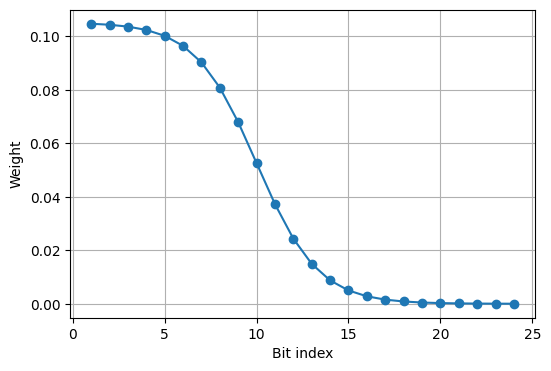

In [325]:
import numpy as np

def sigmoid_weights(K, center=None, steepness=1.0):
    """
    K          : bit数量
    center     : Sigmoid拐点位置
    steepness  : 下降速度
    """

    if center is None:
        center = K / 3

    idx = np.arange(1, K + 1)

    w = 1 / (1 + np.exp(steepness * (idx - center)))

    # 归一化
    w = w / w.sum()

    return w



import numpy as np
import matplotlib.pyplot as plt

K = 24

idx = np.arange(1, K + 1)

center = 10
steepness = 0.6

w = 1/(1+np.exp(steepness*(idx-center)))
w = w/w.sum()

plt.figure(figsize=(6,4))
plt.plot(idx, w, 'o-')
plt.xlabel('Bit index')
plt.ylabel('Weight')
plt.grid(True)
plt.show()

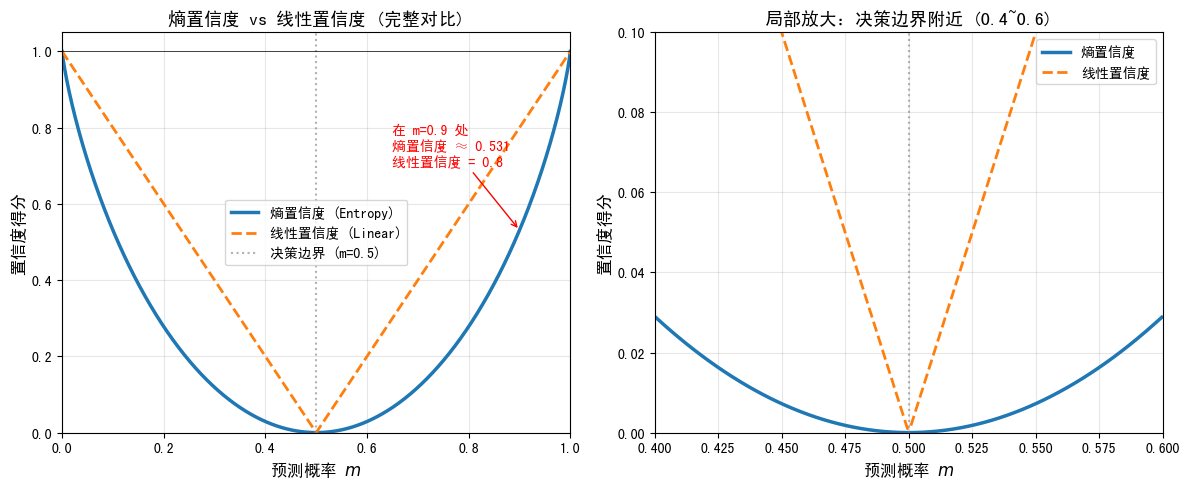

关键概率点的置信度数值对比：
--------------------------------------------------
m = 0.500  ->  熵置信度: 0.0000  |  线性置信度: 0.0000
m = 0.550  ->  熵置信度: 0.0072  |  线性置信度: 0.1000
m = 0.600  ->  熵置信度: 0.0290  |  线性置信度: 0.2000
m = 0.700  ->  熵置信度: 0.1187  |  线性置信度: 0.4000
m = 0.800  ->  熵置信度: 0.2781  |  线性置信度: 0.6000
m = 0.900  ->  熵置信度: 0.5310  |  线性置信度: 0.8000
m = 0.950  ->  熵置信度: 0.7136  |  线性置信度: 0.9000
m = 0.990  ->  熵置信度: 0.9192  |  线性置信度: 0.9800
m = 1.000  ->  熵置信度: 1.0000  |  线性置信度: 1.0000


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 设置中文字体（如果系统支持），否则注释掉或更换为 SimHei
plt.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'SimHei', 'DejaVu Sans'] 
plt.rcParams['axes.unicode_minus'] = False

# ==================== 1. 定义计算公式 ====================
def entropy_confidence(m):
    """
    计算基于二元熵的置信度，使用 log2 直接归一化（等价于除以 ln2）
    c = 1 - H_b(m)，其中 H_b 是以 2 为底的熵
    """
    # 避免 log(0) 的数值问题，将概率钳制在极小值范围内
    eps = 1e-12
    m = np.clip(m, eps, 1 - eps)
    
    # 以 2 为底的二元熵 (最大值为 1)
    H_b = -m * np.log2(m) - (1 - m) * np.log2(1 - m)
    return 1 - H_b

def linear_confidence(m):
    """计算线性距离置信度：2 * |m - 0.5|"""
    return 2 * np.abs(m - 0.5)

# ==================== 2. 生成数据 ====================
m_vals = np.linspace(0, 1, 1000)  # 预测概率从 0 到 1

c_entropy = entropy_confidence(m_vals)
c_linear = linear_confidence(m_vals)

# ==================== 3. 绘制主图 ====================
plt.figure(figsize=(12, 5))

# ---- 子图 1：完整曲线对比 ----
plt.subplot(1, 2, 1)
plt.plot(m_vals, c_entropy, label='熵置信度 (Entropy)', linewidth=2.5, color='#1f77b4')
plt.plot(m_vals, c_linear, label='线性置信度 (Linear)', linewidth=2, linestyle='--', color='#ff7f0e')

# 辅助线
plt.axvline(x=0.5, color='gray', linestyle=':', alpha=0.6, label='决策边界 (m=0.5)')
plt.axhline(y=0, color='black', linewidth=0.5)
plt.axhline(y=1, color='black', linewidth=0.5)

plt.xlabel('预测概率 $m$', fontsize=12)
plt.ylabel('置信度得分', fontsize=12)
plt.title('熵置信度 vs 线性置信度 (完整对比)', fontsize=13)
plt.grid(True, alpha=0.3)
plt.legend(loc='best')
plt.xlim(0, 1)
plt.ylim(0, 1.05)

# 标注关键差异点（概率 0.9 处的差距）
plt.annotate('在 m=0.9 处\n熵置信度 ≈ 0.531\n线性置信度 = 0.8', 
             xy=(0.9, 0.531), xytext=(0.65, 0.7),
             arrowprops=dict(arrowstyle='->', color='red'), fontsize=10, color='red')

# ---- 子图 2：重点放大模糊区域 (0.4 ~ 0.6) ----
plt.subplot(1, 2, 2)
mask = (m_vals >= 0.4) & (m_vals <= 0.6)
m_zoom = m_vals[mask]
c_entropy_zoom = c_entropy[mask]
c_linear_zoom = c_linear[mask]

plt.plot(m_zoom, c_entropy_zoom, label='熵置信度', linewidth=2.5, color='#1f77b4')
plt.plot(m_zoom, c_linear_zoom, label='线性置信度', linewidth=2, linestyle='--', color='#ff7f0e')

plt.axvline(x=0.5, color='gray', linestyle=':', alpha=0.6)
plt.xlabel('预测概率 $m$', fontsize=12)
plt.ylabel('置信度得分', fontsize=12)
plt.title('局部放大：决策边界附近 (0.4~0.6)', fontsize=13)
plt.grid(True, alpha=0.3)
plt.legend(loc='best')
plt.xlim(0.4, 0.6)
plt.ylim(0, 0.1)  # 注意 y 轴尺度，显示熵置信度在边界处趋近于 0 的“钝化”平滑

plt.tight_layout()
plt.show()

# ==================== 4. 打印特征数值对比 ====================
print("="*50)
print("关键概率点的置信度数值对比：")
print("-"*50)
test_probs = [0.5, 0.55, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99, 1.0]
for p in test_probs:
    # 针对端点做数值保护
    p_clip = np.clip(p, 1e-12, 1-1e-12)
    H = -p_clip * np.log2(p_clip) - (1-p_clip) * np.log2(1-p_clip)
    c_ent = 1 - H
    c_lin = 2 * abs(p - 0.5)
    print(f"m = {p:.3f}  ->  熵置信度: {c_ent:.4f}  |  线性置信度: {c_lin:.4f}")

In [2]:
import torch

# 1. 查看 PyTorch 版本
print(f"PyTorch 版本: {torch.__version__}")

# 2. 检查 CUDA 是否可用及查看 GPU 型号
if torch.cuda.is_available():
    print(f"CUDA 可用: True")
    print(f"GPU 数量: {torch.cuda.device_count()}")
    # 遍历显示所有 GPU 型号
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i} 型号: {torch.cuda.get_device_name(i)}")
else:
    print("CUDA 不可用 (未检测到 NVIDIA GPU 或未安装 GPU 版 PyTorch)")


PyTorch 版本: 1.10.0+cu111
CUDA 可用: True
GPU 数量: 1
GPU 0 型号: NVIDIA GeForce RTX 4060 Laptop GPU


In [ ]:
import json
import os
import re

def extract_im_id(path):
    """
    从图像路径中提取 im_id。
    示例：'datasets/geometry/test/000000/rgb/000000.jpg' -> 1
    """
    filename = os.path.basename(path)          # '000000.jpg'
    num_str = os.path.splitext(filename)[0]    # '000000'
    return int(num_str)                 # 0 + 1 = 1

# 生成记录列表
records = []
for path in test_rgb_files[obj_id]:
        im_id = extract_im_id(path)
        records.append({
            "im_id": im_id,
            "inst_count": 1,
            "obj_id": obj_id+1,
            "scene_id": 0
        })

# 为匹配示例顺序，按 im_id 升序，同一 im_id 内按自定义 obj_id 顺序排列
obj_order = [25, 2, 29, 30]  # 示例中的出现顺序
records.sort(key=lambda x: (x["im_id"], obj_order.index(x["obj_id"]) if x["obj_id"] in obj_order else float('inf')))

# 输出 JSON
# print(json.dumps(records, indent=2))

# 写入 JSON 文件
output_file = "output.json"
with open(output_file, "w", encoding="utf-8") as f:
    json.dump(records, f, indent=2, ensure_ascii=False)